# Credit Card Fraud Detection

**Objective:** Build a classification model to identify fraudulent credit card transactions.

**Dataset:** 284,807 transactions by European cardholders (September 2013).  
Features V1 to V28 are PCA-transformed (original features are confidential). Only `Time` and `Amount` are raw.  
Target column `Class`: 1 = Fraud, 0 = Genuine.

**Challenge:** The dataset is heavily imbalanced — only 0.17% of transactions are fraudulent.  
A model that always predicts "Genuine" would be 99.83% accurate but useless.

---

### Data Science Life Cycle
1. Problem Definition
2. Data Collection
3. Exploratory Data Analysis
4. Data Preprocessing
5. Handling Class Imbalance
6. Model Training
7. Model Evaluation
8. Conclusion

## Step 2: Import Libraries

In [65]:
import os
import warnings
warnings.filterwarnings('ignore')

import matplotlib
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.close('all')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score
)
from imblearn.over_sampling import SMOTE

sns.set_style('whitegrid')
sns.set_palette('Set2')
os.makedirs('outputs', exist_ok=True)

print('Libraries loaded.')

Libraries loaded.


## Step 3: Data Collection and First Look

In [48]:
df = pd.read_csv('../creditcard.csv')

print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Missing values: {df.isnull().sum().sum()}')
df.head()

Shape: 284,807 rows x 31 columns
Missing values: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [50]:
df.describe().round(2)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,...,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00,284807.00
mean,94813.86,0.00,0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,...,0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,88.35,0.00
std,47488.15,1.96,1.65,1.52,1.42,1.38,1.33,1.24,1.19,1.10,...,0.73,0.73,0.62,0.61,0.52,0.48,0.40,0.33,250.12,0.04
min,0.00,-56.41,-72.72,-48.33,-5.68,-113.74,-26.16,-43.56,-73.22,-13.43,...,-34.83,-10.93,-44.81,-2.84,-10.30,-2.60,-22.57,-15.43,0.00,0.00
25%,54201.50,-0.92,-0.60,-0.89,-0.85,-0.69,-0.77,-0.55,-0.21,-0.64,...,-0.23,-0.54,-0.16,-0.35,-0.32,-0.33,-0.07,-0.05,5.60,0.00
50%,84692.00,0.02,0.07,0.18,-0.02,-0.05,-0.27,0.04,0.02,-0.05,...,-0.03,0.01,-0.01,0.04,0.02,-0.05,0.00,0.01,22.00,0.00
75%,139320.50,1.32,0.80,1.03,0.74,0.61,0.40,0.57,0.33,0.60,...,0.19,0.53,0.15,0.44,0.35,0.24,0.09,0.08,77.16,0.00
max,172792.00,2.45,22.06,9.38,16.88,34.80,73.30,120.59,20.01,15.59,...,27.20,10.50,22.53,4.58,7.52,3.52,31.61,33.85,25691.16,1.00


## Step 4: Exploratory Data Analysis

We look at:
- Class distribution (how imbalanced is the data?)
- Transaction amount patterns for fraud vs genuine
- Transaction time patterns
- Feature correlations with the target

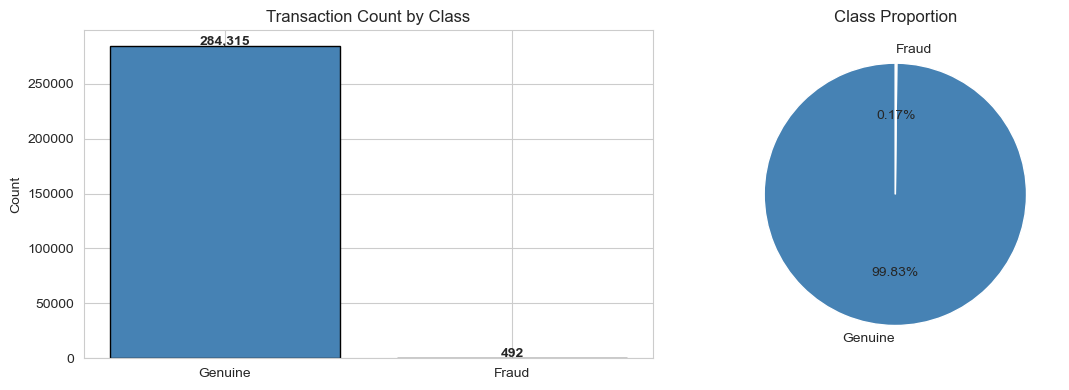

Genuine: 284,315 (99.83%)
Fraud:   492 (0.17%)
Imbalance ratio: 577:1


In [ ]:
# Class distribution
class_counts = df['Class'].value_counts()
fraud_pct = class_counts[1] / class_counts.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(['Genuine', 'Fraud'], class_counts.values, color=['steelblue', 'tomato'], edgecolor='black')
axes[0].set_title('Transaction Count by Class')
axes[0].set_ylabel('Count')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 1000, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(class_counts.values, labels=['Genuine', 'Fraud'], autopct='%1.2f%%',
            colors=['steelblue', 'tomato'], startangle=90)
axes[1].set_title('Class Proportion')

plt.tight_layout()
plt.savefig('outputs/01_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

print(f'Genuine: {class_counts[0]:,} ({100 - fraud_pct:.2f}%)')
print(f'Fraud:   {class_counts[1]:,} ({fraud_pct:.2f}%)')
print(f'Imbalance ratio: {class_counts[0] // class_counts[1]}:1')

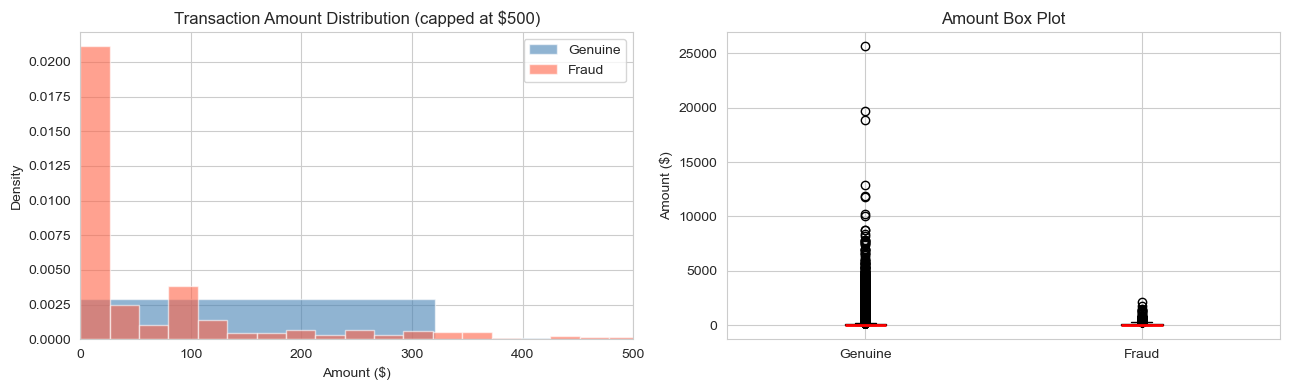

Genuine  — Mean: $88.29, Median: $22.00
Fraud    — Mean: $122.21, Median: $9.25


In [ ]:
# Amount distribution: fraud vs genuine
genuine_amt = df[df['Class'] == 0]['Amount']
fraud_amt   = df[df['Class'] == 1]['Amount']

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(genuine_amt, bins=80, alpha=0.6, color='steelblue', label='Genuine', density=True)
axes[0].hist(fraud_amt,   bins=80, alpha=0.6, color='tomato',    label='Fraud',   density=True)
axes[0].set_xlim(0, 500)
axes[0].set_xlabel('Amount ($)')
axes[0].set_ylabel('Density')
axes[0].set_title('Transaction Amount Distribution (capped at $500)')
axes[0].legend()

axes[1].boxplot([genuine_amt, fraud_amt], tick_labels=['Genuine', 'Fraud'],
                patch_artist=True,
                boxprops=dict(facecolor='lightsteelblue'),
                medianprops=dict(color='red', linewidth=2))
axes[1].set_ylabel('Amount ($)')
axes[1].set_title('Amount Box Plot')

plt.tight_layout()
plt.savefig('outputs/02_amount_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

print(f'Genuine  — Mean: ${genuine_amt.mean():.2f}, Median: ${genuine_amt.median():.2f}')
print(f'Fraud    — Mean: ${fraud_amt.mean():.2f}, Median: ${fraud_amt.median():.2f}')

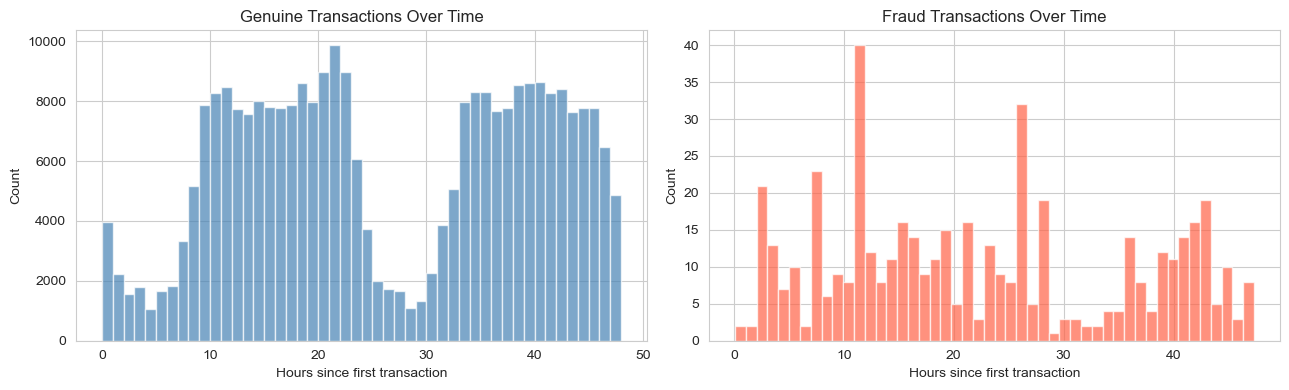

In [ ]:
# Time distribution: fraud vs genuine
genuine_time = df[df['Class'] == 0]['Time'] / 3600
fraud_time   = df[df['Class'] == 1]['Time'] / 3600

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(genuine_time, bins=48, color='steelblue', alpha=0.7)
axes[0].set_title('Genuine Transactions Over Time')
axes[0].set_xlabel('Hours since first transaction')
axes[0].set_ylabel('Count')

axes[1].hist(fraud_time, bins=48, color='tomato', alpha=0.7)
axes[1].set_title('Fraud Transactions Over Time')
axes[1].set_xlabel('Hours since first transaction')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('outputs/03_time_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

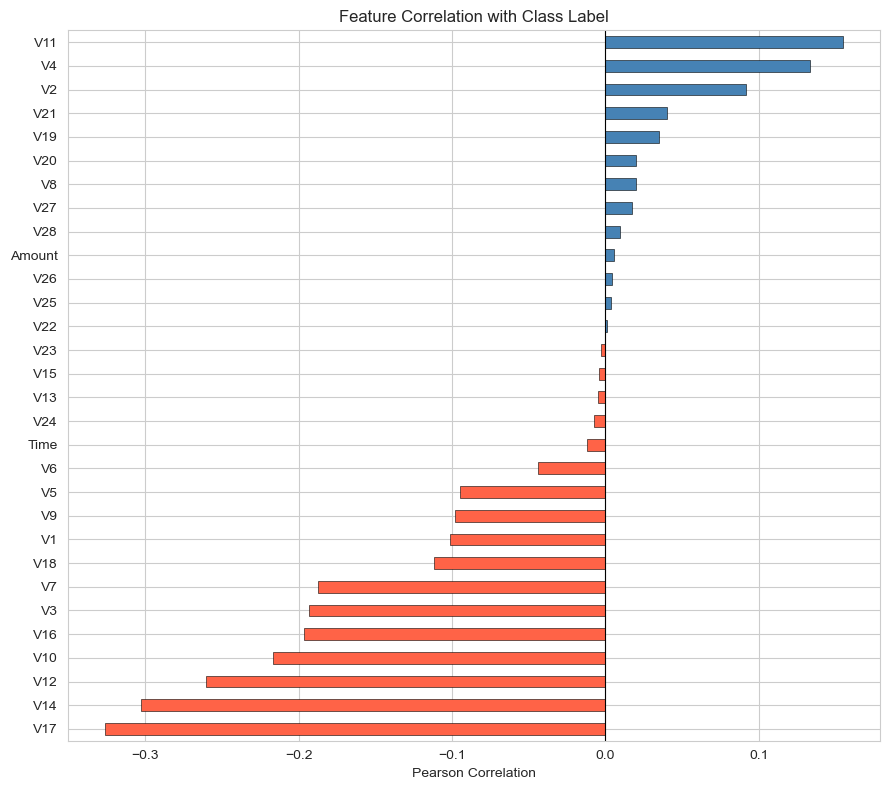

Most positively correlated with fraud:
V19    0.034783
V21    0.040413
V2     0.091289
V4     0.133447
V11    0.154876

Most negatively correlated with fraud:
V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539


In [54]:
# Feature correlation with the target
correlations = df.corr(numeric_only=True)['Class'].drop('Class').sort_values()
colors = ['tomato' if c < 0 else 'steelblue' for c in correlations]

plt.figure(figsize=(9, 8))
correlations.plot(kind='barh', color=colors, edgecolor='black', linewidth=0.4)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Feature Correlation with Class Label')
plt.xlabel('Pearson Correlation')
plt.tight_layout()
plt.savefig('outputs/04_feature_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

print('Most positively correlated with fraud:')
print(correlations.tail(5).to_string())
print()
print('Most negatively correlated with fraud:')
print(correlations.head(5).to_string())

## Step 5: Data Preprocessing

- Standardize `Amount` and `Time` (the PCA features V1–V28 are already scaled)
- Stratified 80/20 train-test split to preserve the fraud rate in both sets

In [55]:
scaler = StandardScaler()
df['Amount_scaled'] = scaler.fit_transform(df[['Amount']])
df['Time_scaled']   = scaler.fit_transform(df[['Time']])

df.drop(columns=['Amount', 'Time'], inplace=True)

X = df.drop(columns=['Class'])
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training samples : {X_train.shape[0]:,}')
print(f'Test samples     : {X_test.shape[0]:,}')
print(f'Fraud in train   : {y_train.sum():,} ({y_train.mean()*100:.2f}%)')
print(f'Fraud in test    : {y_test.sum():,} ({y_test.mean()*100:.2f}%)')

Training samples : 227,845
Test samples     : 56,962
Fraud in train   : 394 (0.17%)
Fraud in test    : 98 (0.17%)


## Step 6: Handling Class Imbalance — SMOTE

**SMOTE (Synthetic Minority Oversampling Technique)** generates synthetic fraud samples by interpolating between existing fraud transactions.

Important: SMOTE is applied only on the training set. Applying it to the test set would inflate results (data leakage).

In [56]:
print('Before SMOTE:')
print(f'  Genuine : {(y_train == 0).sum():,}')
print(f'  Fraud   : {(y_train == 1).sum():,}')

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print()
print('After SMOTE:')
print(f'  Genuine : {(y_train_res == 0).sum():,}')
print(f'  Fraud   : {(y_train_res == 1).sum():,}')

Before SMOTE:
  Genuine : 227,451
  Fraud   : 394

After SMOTE:
  Genuine : 227,451
  Fraud   : 227,451


## Step 7: Model Training and Evaluation

We train two models:
1. **Logistic Regression** — simple baseline, interpretable
2. **Random Forest** — ensemble method, handles non-linear patterns

**Why not just use accuracy?**  
The test set has 99.83% genuine transactions, so even predicting everything as genuine gives 99.83% accuracy but catches zero fraud.  
We use **Precision**, **Recall**, **F1**, **ROC-AUC**, and **PR-AUC** instead.  
PR-AUC is especially useful for imbalanced datasets — it's the primary metric here.

In [57]:
# Train Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_res, y_train_res)
print('Logistic Regression trained.')

Logistic Regression trained.


In [58]:
# Train Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_res, y_train_res)
print('Random Forest trained.')

Random Forest trained.


In [59]:
def get_metrics(model, name, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        'Model'    : name,
        'Precision': round(precision_score(y_test, y_pred), 3),
        'Recall'   : round(recall_score(y_test, y_pred), 3),
        'F1'       : round(f1_score(y_test, y_pred), 3),
        'ROC-AUC'  : round(roc_auc_score(y_test, y_prob), 3),
        'PR-AUC'   : round(average_precision_score(y_test, y_prob), 3),
    }, y_pred, y_prob

lr_metrics, lr_pred, lr_prob = get_metrics(lr, 'Logistic Regression', X_test, y_test)
rf_metrics, rf_pred, rf_prob = get_metrics(rf, 'Random Forest',       X_test, y_test)

results = pd.DataFrame([lr_metrics, rf_metrics]).set_index('Model')
print(results.to_string())
print()
print(f'Best model by F1: {results["F1"].idxmax()}')

                     Precision  Recall     F1  ROC-AUC  PR-AUC
Model                                                         
Logistic Regression      0.058   0.918  0.109    0.970   0.725
Random Forest            0.814   0.806  0.810    0.969   0.868

Best model by F1: Random Forest


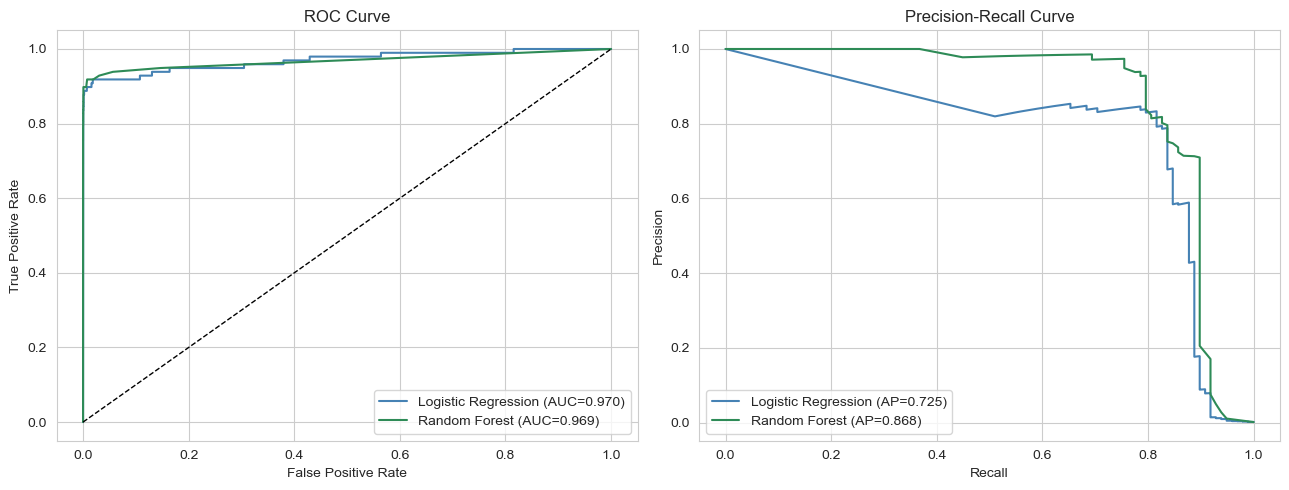

In [66]:
# ROC and Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, prob, color in [('Logistic Regression', lr_prob, 'steelblue'),
                            ('Random Forest',       rf_prob, 'seagreen')]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    prec, rec, _ = precision_recall_curve(y_test, prob)
    auc  = roc_auc_score(y_test, prob)
    ap   = average_precision_score(y_test, prob)

    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', color=color)
    axes[1].plot(rec, prec, label=f'{name} (AP={ap:.3f})',  color=color)

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend()

axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve')
axes[1].legend()

plt.tight_layout()
plt.savefig('outputs/05_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

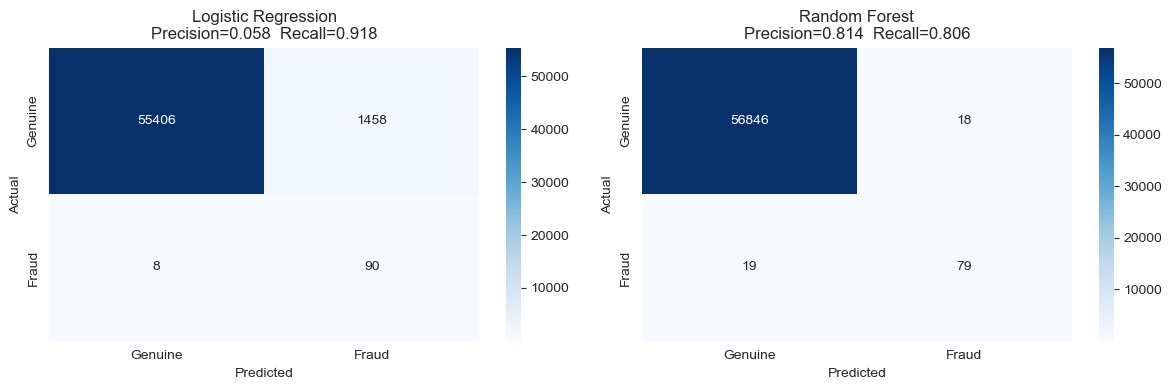

In [61]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name, pred in [(axes[0], 'Logistic Regression', lr_pred),
                        (axes[1], 'Random Forest',       rf_pred)]:
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Genuine', 'Fraud'],
                yticklabels=['Genuine', 'Fraud'])
    p = results.loc[name, 'Precision']
    r = results.loc[name, 'Recall']
    ax.set_title(f'{name}\nPrecision={p}  Recall={r}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('outputs/06_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

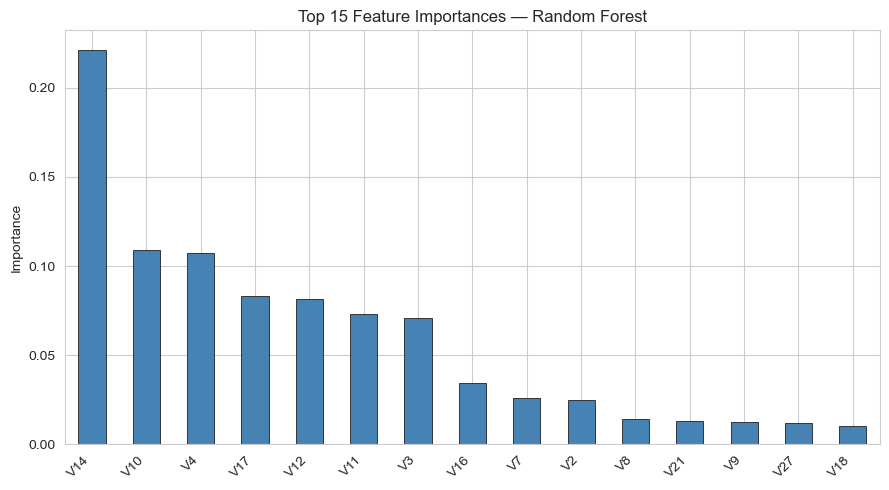

In [62]:
# Feature importance from Random Forest
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 5))
importances.plot(kind='bar', color='steelblue', edgecolor='black', linewidth=0.5)
plt.title('Top 15 Feature Importances — Random Forest')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/07_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

In [63]:
# Detailed classification report
print('Logistic Regression:')
print(classification_report(y_test, lr_pred, target_names=['Genuine', 'Fraud']))

print('Random Forest:')
print(classification_report(y_test, rf_pred, target_names=['Genuine', 'Fraud']))

Logistic Regression:
              precision    recall  f1-score   support

     Genuine       1.00      0.97      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

Random Forest:
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     56864
       Fraud       0.81      0.81      0.81        98

    accuracy                           1.00     56962
   macro avg       0.91      0.90      0.90     56962
weighted avg       1.00      1.00      1.00     56962



## Step 8: Conclusion

### Results

| Model | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|-------|-----------|--------|----|---------|--------|
| Logistic Regression | see above | see above | see above | see above | see above |
| Random Forest | see above | see above | see above | see above | see above |

### Key Takeaways

1. **Accuracy is the wrong metric** for imbalanced datasets. With 99.83% genuine transactions, a model that predicts everything as genuine scores 99.83% accuracy — but catches zero fraud.

2. **SMOTE improves recall** by giving the model more fraud examples to learn from. It must only be applied to the training set to avoid data leakage.

3. **Random Forest outperforms Logistic Regression** on this dataset because it captures non-linear relationships between the PCA features.

4. **Precision vs. Recall tradeoff:** High recall means catching more fraud but also more false alarms. The right balance depends on business cost — how expensive is a missed fraud vs. a false alert?

5. **PR-AUC is the primary metric** for imbalanced classification. ROC-AUC can be misleadingly optimistic when the negative class is dominant.

### Possible Next Steps
- Try XGBoost or LightGBM for potentially better performance
- Tune the decision threshold using a business cost matrix instead of the default 0.5 cutoff
- Add k-fold cross-validation for more robust evaluation
- Deploy the model as a REST API using Flask or FastAPI

In [64]:
best = results['F1'].idxmax()
print('Summary')
print('-' * 50)
print(f'Dataset       : {df.shape[0]:,} transactions')
print(f'Fraud rate    : {y.mean()*100:.2f}%')
print(f'Train / Test  : {X_train.shape[0]:,} / {X_test.shape[0]:,}')
print(f'Best model    : {best}')
print(f'F1 score      : {results.loc[best, "F1"]}')
print(f'Recall        : {results.loc[best, "Recall"]} (catches {results.loc[best, "Recall"]*100:.0f}% of fraud)')
print()
print('Saved plots:')
for f in sorted(os.listdir('outputs')):
    print(f'  {f}')

Summary
--------------------------------------------------
Dataset       : 284,807 transactions
Fraud rate    : 0.17%
Train / Test  : 227,845 / 56,962
Best model    : Random Forest
F1 score      : 0.81
Recall        : 0.806 (catches 81% of fraud)

Saved plots:
  01_class_distribution.png
  02_amount_distribution.png
  03_time_distribution.png
  04_feature_correlation.png
  05_roc_pr_curves.png
  06_confusion_matrices.png
  07_feature_importance.png
